Objective:
 A mall wants to divide its customers into groups based on their:
 Annual income, Spending score
 The marketing team can then create diff startegies for diff cust groups.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
##################################################
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
###################################################
import warnings
warnings.filterwarnings('ignore')

In [ ]:
#load dataset
df=pd.read_csv('/content/Mall_Customers.csv',index_col='CustomerID')
df.tail()

,Gender,Age,Annual Income (k$),Spending Score (1-100)
CustomerID,,,,
196,Female,35,120,79
197,Female,45,126,28
198,Male,32,126,74
199,Male,32,137,18
200,Male,30,137,83


In [ ]:
#understanding data
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 200 entries, 1 to 200
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   Gender                  200 non-null    object
 1   Age                     200 non-null    int64 
 2   Annual Income (k$)      200 non-null    int64 
 3   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(3), object(1)
memory usage: 7.8+ KB


In [ ]:
df.shape

(200, 4)

In [ ]:
df.describe()

,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


In [ ]:
df.isna().sum()

,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.nunique()

,0
Gender,2
Age,51
Annual Income (k$),64
Spending Score (1-100),84


<module 'matplotlib.pyplot' from '/usr/local/lib/python3.13/dist-packages/matplotlib/pyplot.py'>

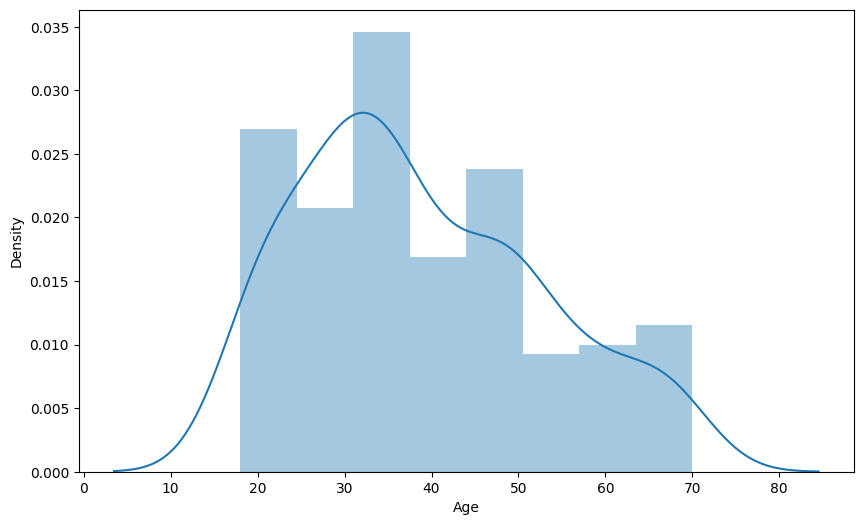

In [ ]:
#EDA:
# look at the distribution of age
plt.figure(figsize=(10,6))
sns.distplot(df['Age'])
plt

<module 'matplotlib.pyplot' from '/usr/local/lib/python3.13/dist-packages/matplotlib/pyplot.py'>

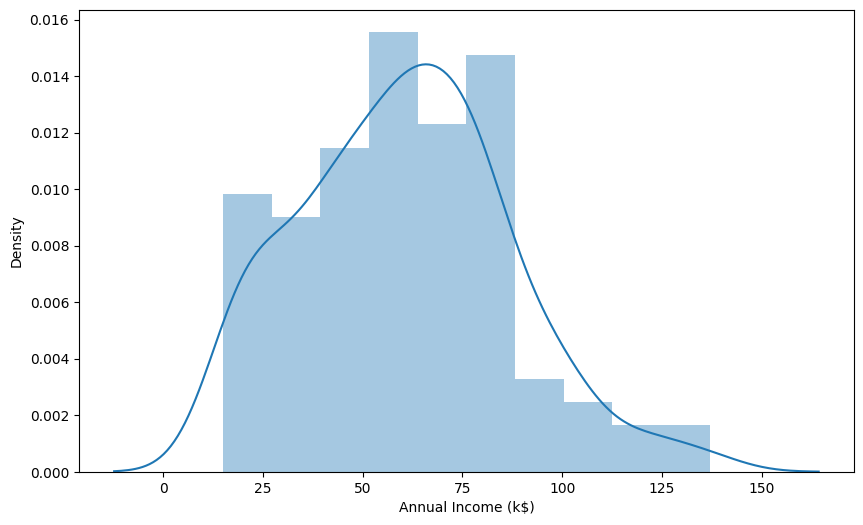

In [ ]:
# Annual Income Distribution
plt.figure(figsize=(10,6))
sns.distplot(df['Annual Income (k$)'])
plt

<module 'matplotlib.pyplot' from '/usr/local/lib/python3.13/dist-packages/matplotlib/pyplot.py'>

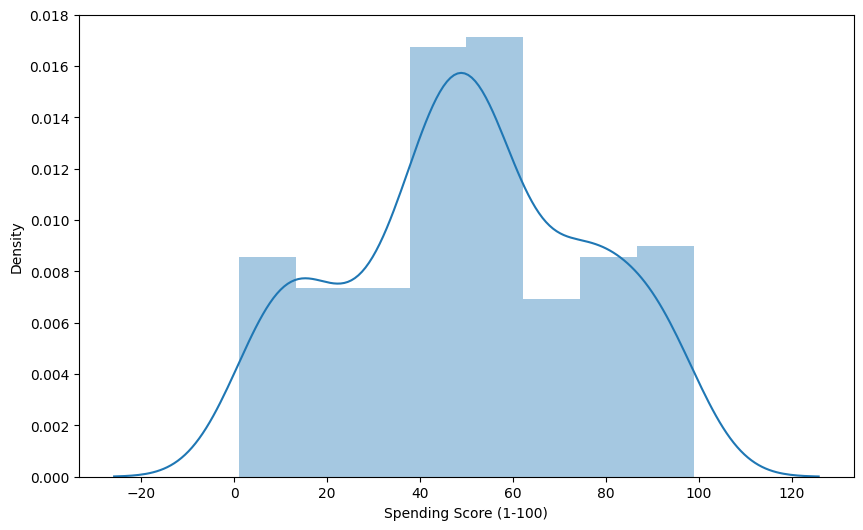

In [ ]:
# spending score distribution
plt.figure(figsize=(10,6))
sns.distplot(df['Spending Score (1-100)'])
plt

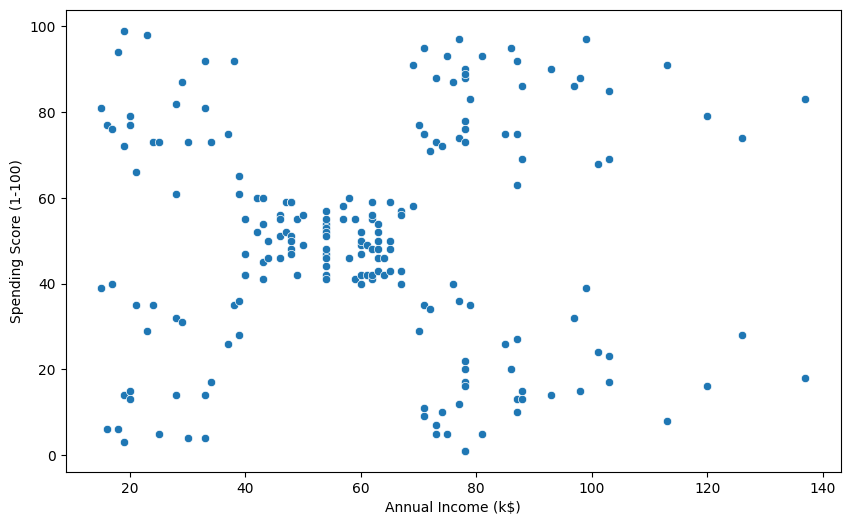

In [ ]:
#Visualizing before clustering
plt.figure(figsize=(10,6))
sns.scatterplot(x='Annual Income (k$)',y='Spending Score (1-100)',data=df)
plt.show()

In [ ]:
df.drop('Gender',axis=1,inplace=True)

In [ ]:
#feature scaling
scaler=StandardScaler()
df_scaled=scaler.fit_transform(df)
df_scaled

array([[-1.42456879, -1.73899919, -0.43480148],
       [-1.28103541, -1.73899919,  1.19570407],
       [-1.3528021 , -1.70082976, -1.71591298],
       [-1.13750203, -1.70082976,  1.04041783],
       [-0.56336851, -1.66266033, -0.39597992],
       [-1.20926872, -1.66266033,  1.00159627],
       [-0.27630176, -1.62449091, -1.71591298],
       [-1.13750203, -1.62449091,  1.70038436],
       [ 1.80493225, -1.58632148, -1.83237767],
       [-0.6351352 , -1.58632148,  0.84631002],
       [ 2.02023231, -1.58632148, -1.4053405 ],
       [-0.27630176, -1.58632148,  1.89449216],
       [ 1.37433211, -1.54815205, -1.36651894],
       [-1.06573534, -1.54815205,  1.04041783],
       [-0.13276838, -1.54815205, -1.44416206],
       [-1.20926872, -1.54815205,  1.11806095],
       [-0.27630176, -1.50998262, -0.59008772],
       [-1.3528021 , -1.50998262,  0.61338066],
       [ 0.94373197, -1.43364376, -0.82301709],
       [-0.27630176, -1.43364376,  1.8556706 ],
       [-0.27630176, -1.39547433, -0.590

In [ ]:
eps=0.4
min_sample=3
dbscan=DBSCAN(eps=eps,min_samples=min_sample)
labels=dbscan.fit_predict(df_scaled)
labels

array([-1,  0, -1,  0,  1,  0, -1, -1, -1,  2, -1, -1, -1,  0, -1,  0,  1,
       -1, -1, -1,  1,  0, -1,  2, -1,  2, -1, -1, -1,  0, -1,  0, -1, -1,
       -1,  0, -1,  2, -1,  0, -1, -1,  3,  4,  3, -1,  3,  4,  4,  4,  3,
        4,  4,  5,  3,  3,  3,  5,  4,  3,  5,  4,  5,  5,  5,  4,  3,  5,
        4,  4,  5,  3,  5,  5,  5,  4,  3,  3,  4,  3,  5,  3,  5,  3,  4,
        3,  5,  4,  3,  3,  5,  4,  3,  3, -1,  4,  3,  4,  3,  4,  4,  3,
        5,  4,  3,  4,  5,  3,  5,  5,  5,  4,  3,  4,  4,  4,  5,  3,  3,
        3,  4,  3, -1,  6,  8,  6, -1,  6, -1,  6,  7,  6,  8,  6,  9,  6,
        7,  6,  9,  6, -1,  6,  8,  6, -1,  6, -1,  6, -1,  6,  7,  6,  7,
        6,  7,  6, -1,  6, -1,  6, -1,  6,  9,  6, -1,  6,  7,  6, -1, -1,
        7,  6,  7,  6, -1,  6, -1,  6, -1,  6, -1,  6, -1,  6, -1,  6, -1,
       -1, -1,  6, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1])

In [ ]:
df['Cluster']=labels
df

,Age,Annual Income (k$),Spending Score (1-100),Cluster
CustomerID,,,,
1,19,15,39,-1
2,21,15,81,0
3,20,16,6,-1
4,23,16,77,0
5,31,17,40,1
...,...,...,...,...
196,35,120,79,-1
197,45,126,28,-1
198,32,126,74,-1


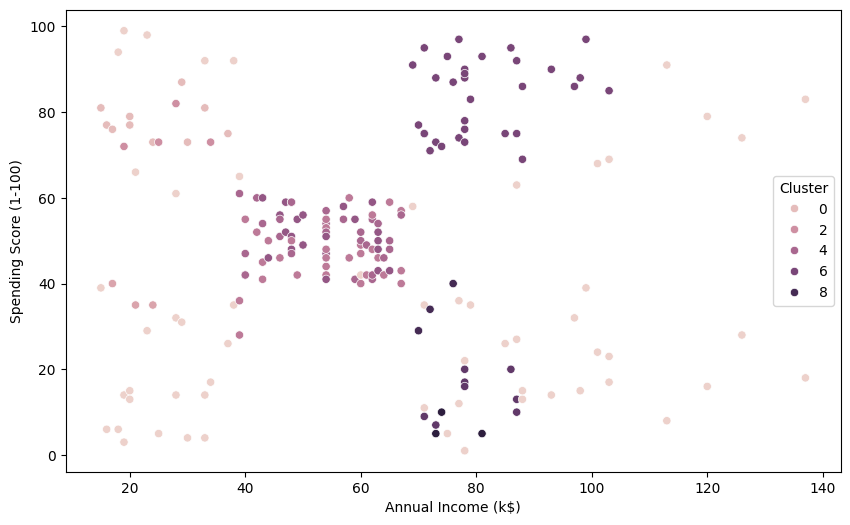

In [ ]:
#Visualization DBSCAN Cluster
plt.figure(figsize=(10,6))
sns.scatterplot(x='Annual Income (k$)',y='Spending Score (1-100)',hue='Cluster',data=df)
plt.show()

In [ ]:
noise=df[df['Cluster']==-1]
noise.shape

(59, 4)

In [ ]:
mask=labels !=-1
x_silhouette=df_scaled[mask]
labels_silhouette=labels[mask]
if len(set(labels_silhouette))>1:
 score=silhouette_score(x_silhouette,labels_silhouette,metric='euclidean')
 print(f'Silhouette Score: {score}')
else:
  print('Silhouette Score: Cannot be calculated')

Silhouette Score: 0.44257547291650223


In [ ]:
eps_values = [0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5]

In [ ]:
for eps in eps_values:

    model = DBSCAN(
        eps=eps,
        min_samples=5
    )

    labels_temp = model.fit_predict(df_scaled)

    clusters = len(
        set(labels_temp)
        - {-1}
    )

    noise = list(labels_temp).count(-1)

    if clusters > 1:

        mask = labels_temp != -1

        score = silhouette_score(
            df_scaled[mask],
            labels_temp[mask]
        )

    else:
        score = np.nan

    print(
        "eps:", eps,
        "clusters:", clusters,
        "noise:", noise,
        "silhouette:", score
    )

eps: 0.2 clusters: 1 noise: 195 silhouette: nan
eps: 0.25 clusters: 5 noise: 165 silhouette: 0.690045211540656
eps: 0.3 clusters: 10 noise: 134 silhouette: 0.5143534975153469
eps: 0.35 clusters: 8 noise: 110 silhouette: 0.4900167116516732
eps: 0.4 clusters: 6 noise: 98 silhouette: 0.5190232911585904
eps: 0.45 clusters: 5 noise: 75 silhouette: 0.5422780428534556
eps: 0.5 clusters: 6 noise: 60 silhouette: 0.481714917862304


In [ ]:
for min_samples in [3, 4, 5, 6, 8, 10]:

    model = DBSCAN(
        eps=0.3,
        min_samples=min_samples
    )

    labels_temp = model.fit_predict(df_scaled)

    clusters = len(
        set(labels_temp)
        - {-1}
    )

    noise = list(labels_temp).count(-1)

    print(
        "min_samples:",
        min_samples,
        "clusters:",
        clusters,
        "noise:",
        noise
    )

min_samples: 3 clusters: 12 noise: 103
min_samples: 4 clusters: 7 noise: 121
min_samples: 5 clusters: 10 noise: 134
min_samples: 6 clusters: 5 noise: 164
min_samples: 8 clusters: 0 noise: 200
min_samples: 10 clusters: 0 noise: 200


In [ ]:
eps=0.4
min_samples=5
dbscan=DBSCAN(eps=eps, min_samples=min_samples)
labels=dbscan.fit_predict(df_scaled)
clusters=len(set(labels)-{-1})
noise=list(labels).count(-1)

In [ ]:
df['Cluster']=labels
df['Cluster'].unique()

array([-1,  0,  2,  1,  3,  4,  5])

In [ ]:
#noise point
noise_count=list(labels).count(-1)
noise_count

98

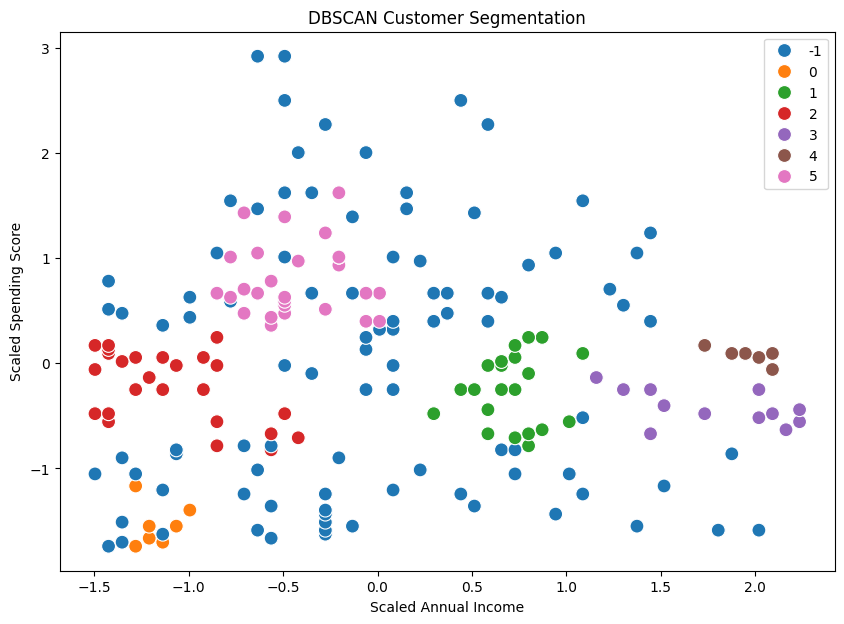

In [ ]:
plt.figure(figsize=(10,7))

sns.scatterplot(
    x=df_scaled[:,0],
    y=df_scaled[:,1],
    hue=labels,
    palette="tab10",
    s=100
)

plt.xlabel(
    "Scaled Annual Income"
)

plt.ylabel(
    "Scaled Spending Score"
)

plt.title(
    "DBSCAN Customer Segmentation"
)

plt.show()

In [ ]:
summary = (
    df[df["Cluster"] != -1]
    .groupby("Cluster")
    .agg(
        Customers=("Age", "count"),
        Avg_Age=("Age", "mean"),
        Avg_Income=(
            "Annual Income (k$)",
            "mean"
        ),
        Avg_Spending=(
            "Spending Score (1-100)",
            "mean"
        )
    )
)

print(summary)

         Customers    Avg_Age  Avg_Income  Avg_Spending
Cluster                                                
0                7  22.571429   20.285714     76.571429
1               22  48.772727   54.363636     48.136364
2               25  23.600000   54.760000     51.800000
3               13  63.384615   49.538462     51.538462
4                7  66.142857   62.571429     50.000000
5               28  32.571429   80.750000     83.000000


In [ ]:
# ==========================================
# 16. Silhouette Score
# ==========================================

mask = labels != -1

if len(set(labels[mask])) > 1:

    score = silhouette_score(
        df_scaled[mask],
        labels[mask]
    )

    print(
        "Silhouette Score:",
        score
    )
else:

    print(
        "Cannot calculate Silhouette Score"
    )

Silhouette Score: 0.5190232911585904
